# Instituto / Universidad: **CENTRO UNIVERSITARIO UAEM ZUMPANGO**

## Programa Educativo: Ingeniería en Computación

### Asignatura: Investigación de Operaciones

---

# Práctica 2. Ruta Crítica (PERT/CPM)

**Actividad integradora:** Implementación de Modelos de Investigación de Operaciones mediante Python y Jupyter Notebook

**Periodo:** 2026-B

**Integrantes del equipo:**

| No. | Nombre completo |
|:---:|:----------------|
| 1 | Fernando Dante Rodriguez Silva |  
| 2 | Jonathan Alberto López Fabián |
| 3 | Brayan Michel Aguilar Torres |  

**Fecha de elaboración:** 16 de noviembre de 2026

**Herramientas:** Python 3, Jupyter Notebook, NetworkX, Matplotlib, NumPy, Pandas y SciPy.

---
# 1. Título del problema

**Planeación y control del proyecto de desarrollo y despliegue de una aplicación web en la nube mediante el Método de la Ruta Crítica (CPM)**


---
# 2. Descripción y planteamiento

Una empresa de software debe desarrollar y poner en producción una aplicación web en la nube. El proyecto se descompone en **13 actividades** con duración estimada en **días** y con relaciones de precedencia entre ellas (por ejemplo, el *backend* no puede comenzar hasta terminar el diseño de la arquitectura).

Se busca responder las **preguntas clave de la administración de proyectos**:

- ¿Cuándo sería lo más pronto que el proyecto esté terminado?
- ¿Qué actividades son **críticas** (cualquier retraso en ellas retrasa todo el proyecto)?
- ¿Cuánta **holgura** tienen las demás actividades?

**Relación con las Tecnologías de la Información:** CPM se utiliza para planear proyectos de software, migraciones a la nube, despliegues de infraestructura y lanzamientos de producto, y permite decidir en qué actividades concentrar recursos (por ejemplo, desarrolladores o ingenieros DevOps).

**Representación utilizada:** red con **actividades en los nodos (AEN)**. Cada nodo se dibuja con la notación vista en clase: **fila superior = ES | EF** (tiempos más cercanos, calculados en la pasada hacia adelante con **sumas**), **fila central = actividad y duración**, **fila inferior = LS | LF** (tiempos más lejanos, calculados en la pasada hacia atrás con **restas**).


---
# 3. Formulación matemática

Sea $t_i$ la duración de la actividad $i$, $P(i)$ el conjunto de sus predecesoras inmediatas y $S(i)$ el de sus sucesoras inmediatas.

**Pasada hacia adelante** (inicio y fin más cercanos):

$$ES_i=\max_{p\in P(i)} EF_p \quad (ES_i=0 \text{ si no tiene predecesoras}), \qquad EF_i=ES_i+t_i$$

**Duración del proyecto:**

$$T=\max_i EF_i$$

**Pasada hacia atrás** (inicio y fin más lejanos), partiendo de las actividades finales con $LF_i=T$:

$$LF_i=\min_{s\in S(i)} LS_s, \qquad LS_i=LF_i-t_i$$

**Holgura (slack):**

$$H_i=LS_i-ES_i=LF_i-EF_i$$

Una actividad es **crítica** si $H_i=0$. La **ruta crítica** es la secuencia de actividades críticas que conecta el inicio con el fin del proyecto y equivale a la **ruta más larga** de la red.

*Equivalente en programación lineal:* minimizar $T$ sujeto a $s_j\ge s_i+t_i$ para cada precedencia $i\to j$ y $T\ge s_i+t_i$ para toda $i$, con $s_i\ge 0$ (inicio de cada actividad).

---
# 4. Importación de bibliotecas

In [1]:
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

print("NumPy    :", np.__version__)
print("Pandas   :", pd.__version__)
print("NetworkX :", nx.__version__)
print("Bibliotecas importadas correctamente.")

NumPy    : 2.5.4
Pandas   : 3.0.6
NetworkX : 3.7
Bibliotecas importadas correctamente.


---
# 5. Definición de datos

Se definen las **13 actividades** del proyecto con su descripción, duración (días) y predecesoras inmediatas. Los datos se guardan en el archivo complementario `p2_actividades_proyecto.csv`.

Se construye además un **grafo dirigido** $G$ donde cada nodo es una actividad y cada arco $(i\to j)$ indica que $i$ precede inmediatamente a $j$. Se verifica que **no existan ciclos** (un proyecto no puede tener dependencias circulares).

In [2]:
actividades = {
    #  id: (descripción,                                   días, predecesoras)
    "A": ("Levantamiento de requerimientos",                3, []),
    "B": ("Arquitectura y modelo de datos",                 4, ["A"]),
    "C": ("Diseño de interfaz UI/UX",                       5, ["A"]),
    "D": ("Configuración de infraestructura en la nube",    3, ["B"]),
    "E": ("Desarrollo del backend (API REST)",              8, ["B"]),
    "F": ("Desarrollo del frontend",                        6, ["C"]),
    "G": ("Configuración del pipeline CI/CD",               2, ["D"]),
    "H": ("Integración frontend-backend",                   3, ["E", "F"]),
    "I": ("Pruebas unitarias del backend",                  4, ["E"]),
    "J": ("Pruebas de integración y seguridad",             5, ["H", "I"]),
    "K": ("Despliegue en producción",                       2, ["G", "J"]),
    "L": ("Documentación y capacitación",                   4, ["H"]),
    "M": ("Cierre y entrega al cliente",                    1, ["K", "L"]),
}

df_act = pd.DataFrame(
    [(k, d, t, ", ".join(p) if p else "-") for k, (d, t, p) in actividades.items()],
    columns=["Actividad", "Descripción", "Duración (días)", "Predecesoras"])
df_act.to_csv("p2_actividades_proyecto.csv", index=False)
print(df_act.to_string(index=False))
print("\nNúmero de actividades:", len(actividades))

dur = {k: v[1] for k, v in actividades.items()}

G = nx.DiGraph()
G.add_nodes_from(actividades)
for k, (_, _, preds) in actividades.items():
    for p in preds:
        G.add_edge(p, k)

print("Número de relaciones de precedencia:", G.number_of_edges())
print("¿La red es un grafo dirigido acíclico (sin ciclos)? ->", nx.is_directed_acyclic_graph(G))

# Niveles de la red (generaciones topologicas): actividades que se pueden calcular juntas
gens = [sorted(g) for g in nx.topological_generations(G)]
gen_idx = {k: i for i, g in enumerate(gens) for k in g}
for i, g in enumerate(gens):
    print(f"Nivel {i}: {g}")

# Fila (posicion vertical) de cada actividad para dibujar la red sin cruces
y_fila = {"A": 0, "B": 1, "C": -1, "D": 1, "E": 0, "F": -1, "G": 1,
          "H": -1, "I": 0, "J": 0, "K": 0, "L": -1, "M": 0}

Actividad                                 Descripción  Duración (días) Predecesoras
        A             Levantamiento de requerimientos                3            -
        B              Arquitectura y modelo de datos                4            A
        C                    Diseño de interfaz UI/UX                5            A
        D Configuración de infraestructura en la nube                3            B
        E           Desarrollo del backend (API REST)                8            B
        F                     Desarrollo del frontend                6            C
        G            Configuración del pipeline CI/CD                2            D
        H                Integración frontend-backend                3         E, F
        I               Pruebas unitarias del backend                4            E
        J          Pruebas de integración y seguridad                5         H, I
        K                    Despliegue en producción                2      

---
## 5.1 Función de graficación de la red AEN

La función `dibujar_red` dibuja cada actividad como una caja de tres filas: **ES | EF** arriba, **actividad (t)** al centro y **LS | LF** abajo. Las casillas se van llenando conforme avanza el algoritmo: **azul** = tiempos de la pasada hacia adelante, **amarillo** = tiempos de la pasada hacia atrás, **rojo** = actividad crítica. El nivel que se está calculando se enmarca en **naranja**.

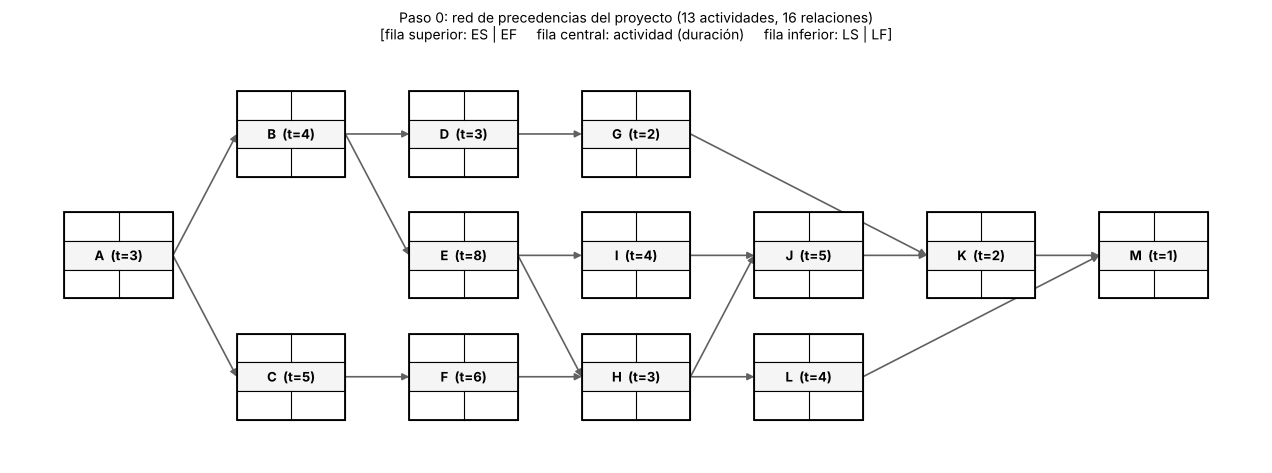

In [3]:
def dibujar_red(vals, titulo, resaltar=(), criticos=(), arcos_criticos=(), ax=None):
    propio = ax is None
    if propio:
        fig, ax = plt.subplots(figsize=(13, 4.7))
    W, H, DX, DY = 1.7, 1.35, 2.7, 1.9
    centro = {k: (gen_idx[k] * DX, y_fila[k] * DY) for k in actividades}

    for u, v in G.edges():
        crit = (u, v) in arcos_criticos
        ax.annotate("", xy=(centro[v][0] - W / 2, centro[v][1]), xytext=(centro[u][0] + W / 2, centro[u][1]),
                    arrowprops=dict(arrowstyle="-|>", color="#d32f2f" if crit else "#616161",
                                    lw=2.6 if crit else 1.2, shrinkA=0, shrinkB=0), zorder=1)

    for k, (cx, cy) in centro.items():
        v = vals[k]
        es_crit = k in criticos
        x0, y0 = cx - W / 2, cy - H / 2
        fila_sup = "#bbdefb" if v["ES"] is not None else "white"
        fila_inf = "#fff59d" if v["LS"] is not None else "white"
        fila_med = "#ffcdd2" if es_crit else "#f5f5f5"
        borde = "#ef6c00" if k in resaltar else ("#d32f2f" if es_crit else "black")
        grosor = 3.2 if (k in resaltar or es_crit) else 1.3
        ax.add_patch(mpatches.Rectangle((x0, y0 + 2 * H / 3), W, H / 3, fc=fila_sup, ec="black", lw=0.8, zorder=2))
        ax.add_patch(mpatches.Rectangle((x0, y0 + H / 3), W, H / 3, fc=fila_med, ec="black", lw=0.8, zorder=2))
        ax.add_patch(mpatches.Rectangle((x0, y0), W, H / 3, fc=fila_inf, ec="black", lw=0.8, zorder=2))
        ax.add_patch(mpatches.Rectangle((x0, y0), W, H, fc="none", ec=borde, lw=grosor, zorder=3))
        ax.plot([cx, cx], [y0 + 2 * H / 3, y0 + H], color="black", lw=0.8, zorder=3)
        ax.plot([cx, cx], [y0, y0 + H / 3], color="black", lw=0.8, zorder=3)
        txt = lambda x: "" if x is None else str(x)
        ax.text(cx - W / 4, cy + H / 3, txt(v["ES"]), ha="center", va="center", fontsize=10, zorder=4)
        ax.text(cx + W / 4, cy + H / 3, txt(v["EF"]), ha="center", va="center", fontsize=10, zorder=4)
        ax.text(cx, cy, f"{k}  (t={dur[k]})", ha="center", va="center", fontsize=9.5, fontweight="bold", zorder=4)
        ax.text(cx - W / 4, cy - H / 3, txt(v["LS"]), ha="center", va="center", fontsize=10, zorder=4)
        ax.text(cx + W / 4, cy - H / 3, txt(v["LF"]), ha="center", va="center", fontsize=10, zorder=4)

    ax.set_xlim(-W, (len(gens) - 1) * DX + W)
    ax.set_ylim(-DY - H, DY + H)
    ax.set_aspect("equal")
    ax.axis("off")
    ax.set_title(titulo + "\n[fila superior: ES | EF     fila central: actividad (duración)     fila inferior: LS | LF]", fontsize=10)
    if propio:
        plt.tight_layout()
        plt.show()


# Diccionario de tiempos (vacío al inicio)
vals = {k: {"ES": None, "EF": None, "LS": None, "LF": None} for k in actividades}

dibujar_red(vals, f"Paso 0: red de precedencias del proyecto ({len(actividades)} actividades, {G.number_of_edges()} relaciones)")

---
# 6. Desarrollo del algoritmo

## 6.1 Implementación de la pasada hacia adelante

Se implementa como un **generador** que procesa **un nivel de la red por cada llamada** a `next()`. Para cada actividad:

1. $ES$ = el **máximo** de los $EF$ de sus predecesoras (0 si no tiene).
2. $EF = ES + t$ (**suma**).

Así se ejecuta el algoritmo celda por celda y se grafica el estado de la red en cada paso.

In [4]:
def pasada_adelante():
    for nivel, grupo in enumerate(gens):
        filas = []
        for k in grupo:
            preds = list(G.predecessors(k))
            ES = max([vals[p]["EF"] for p in preds], default=0)
            EF = ES + dur[k]
            vals[k]["ES"], vals[k]["EF"] = ES, EF
            if preds:
                lista = ", ".join("EF_" + p + "=" + str(vals[p]["EF"]) for p in preds)
                f_es = "ES = max(" + lista + ") = " + str(ES)
            else:
                f_es = "ES = 0 (no tiene predecesoras)"
            f_ef = "EF = ES + t = " + str(ES) + " + " + str(dur[k]) + " = " + str(EF)
            filas.append((k, f_es, f_ef))
        yield nivel, filas


def mostrar_adelante(nivel, filas):
    print(f"PASADA HACIA ADELANTE - Nivel {nivel}: actividades {gens[nivel]}\n")
    for k, f_es, f_ef in filas:
        print(f"  Actividad {k}:  {f_es}   ->   {f_ef}")
    dibujar_red(vals, f"Pasada hacia adelante - nivel {nivel}", resaltar=gens[nivel])


adelante = pasada_adelante()
print("Generador de la pasada hacia adelante listo.")

Generador de la pasada hacia adelante listo.


---
# 7. Ejecución paso a paso

## 7.1 Pasada hacia adelante (suma): $ES$ y $EF$

Cada celda calcula un nivel de la red. Observe cómo cuando una actividad tiene **varios predecesores** (por ejemplo H, J, K y M) su $ES$ es el **máximo** de los $EF$ de todos ellos.

### Nivel 0

Nivel 0 — **A** no tiene predecesoras: $ES=0$.

PASADA HACIA ADELANTE - Nivel 0: actividades ['A']

  Actividad A:  ES = 0 (no tiene predecesoras)   ->   EF = ES + t = 0 + 3 = 3


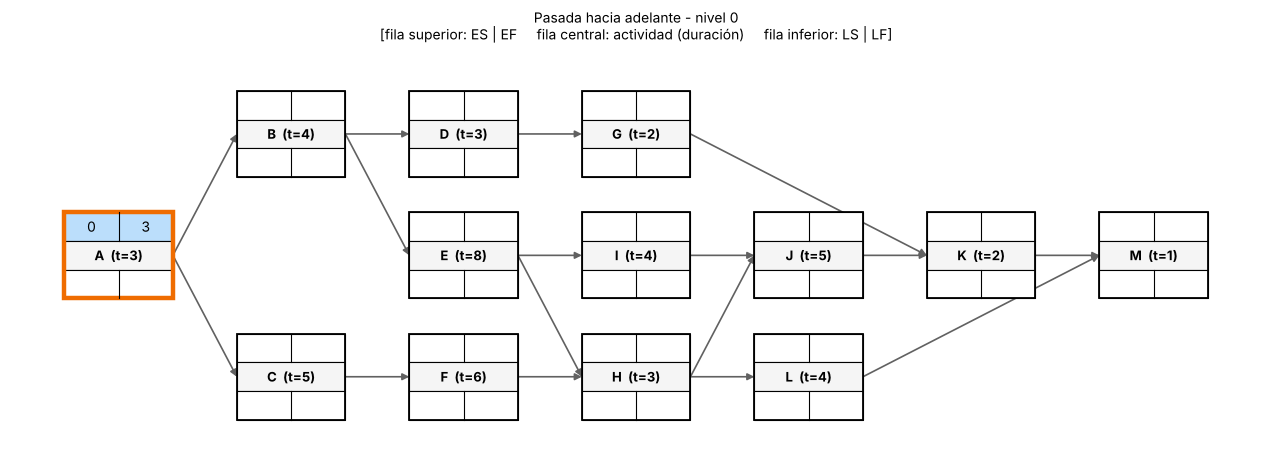

In [5]:
nivel, filas = next(adelante)
mostrar_adelante(nivel, filas)

### Nivel 1

Nivel 1 — **B** y **C** dependen sólo de A, por lo que $ES=EF_A$.

PASADA HACIA ADELANTE - Nivel 1: actividades ['B', 'C']

  Actividad B:  ES = max(EF_A=3) = 3   ->   EF = ES + t = 3 + 4 = 7
  Actividad C:  ES = max(EF_A=3) = 3   ->   EF = ES + t = 3 + 5 = 8


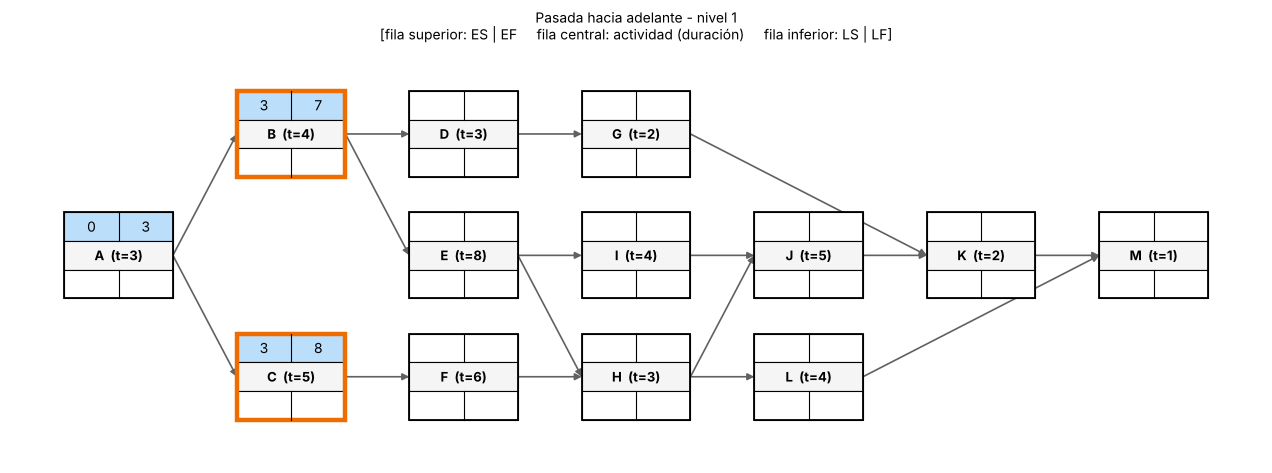

In [6]:
nivel, filas = next(adelante)
mostrar_adelante(nivel, filas)

### Nivel 2

Nivel 2 — **D** y **E** siguen a B; **F** sigue a C.

PASADA HACIA ADELANTE - Nivel 2: actividades ['D', 'E', 'F']

  Actividad D:  ES = max(EF_B=7) = 7   ->   EF = ES + t = 7 + 3 = 10
  Actividad E:  ES = max(EF_B=7) = 7   ->   EF = ES + t = 7 + 8 = 15
  Actividad F:  ES = max(EF_C=8) = 8   ->   EF = ES + t = 8 + 6 = 14


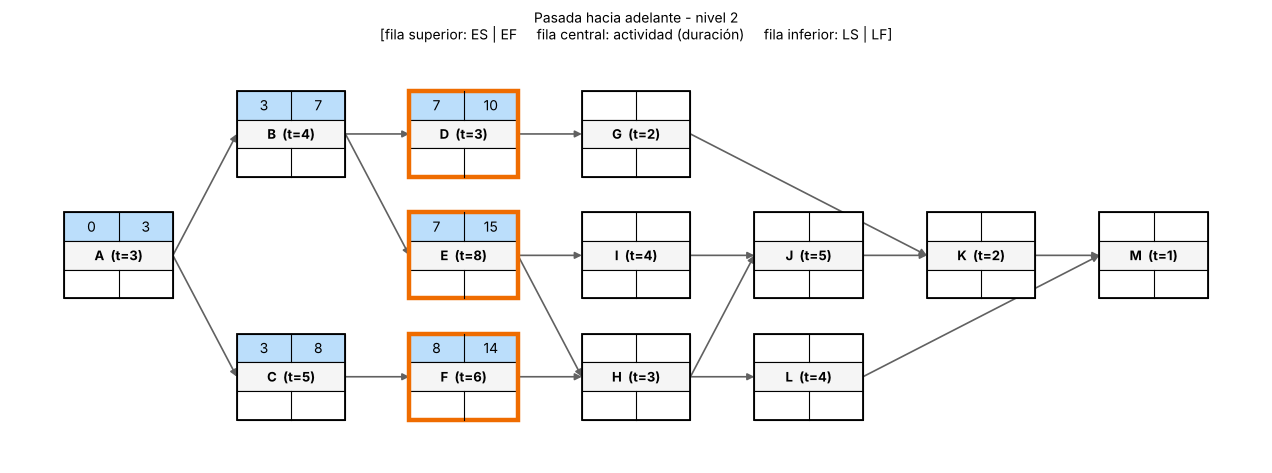

In [7]:
nivel, filas = next(adelante)
mostrar_adelante(nivel, filas)

### Nivel 3

Nivel 3 — **G** sigue a D; **I** sigue a E; **H** tiene dos predecesoras (E y F) y toma el **mayor** $EF$.

PASADA HACIA ADELANTE - Nivel 3: actividades ['G', 'H', 'I']

  Actividad G:  ES = max(EF_D=10) = 10   ->   EF = ES + t = 10 + 2 = 12
  Actividad H:  ES = max(EF_E=15, EF_F=14) = 15   ->   EF = ES + t = 15 + 3 = 18
  Actividad I:  ES = max(EF_E=15) = 15   ->   EF = ES + t = 15 + 4 = 19


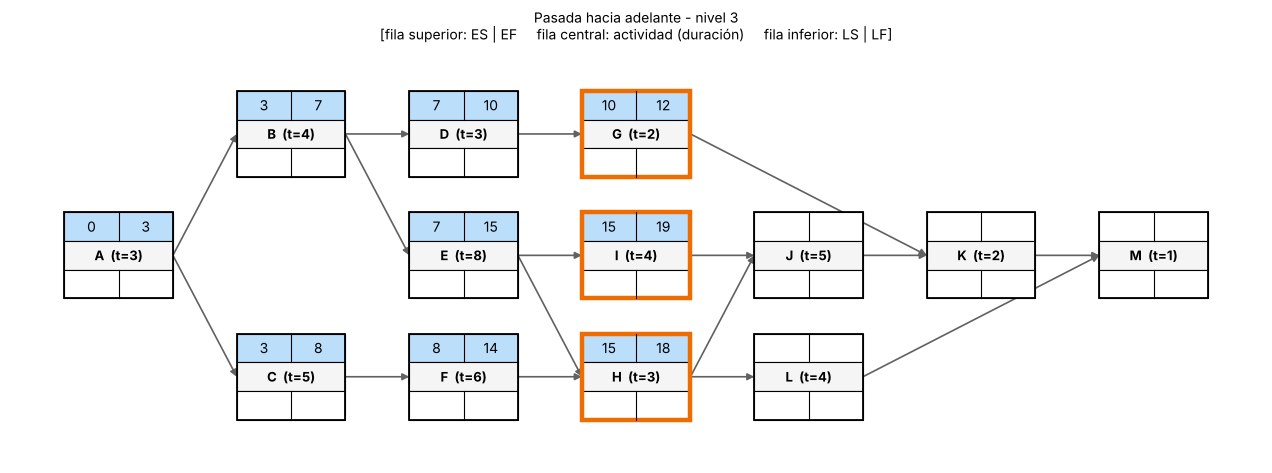

In [8]:
nivel, filas = next(adelante)
mostrar_adelante(nivel, filas)

### Nivel 4

Nivel 4 — **J** espera a H e I; **L** sigue a H.

PASADA HACIA ADELANTE - Nivel 4: actividades ['J', 'L']

  Actividad J:  ES = max(EF_H=18, EF_I=19) = 19   ->   EF = ES + t = 19 + 5 = 24
  Actividad L:  ES = max(EF_H=18) = 18   ->   EF = ES + t = 18 + 4 = 22


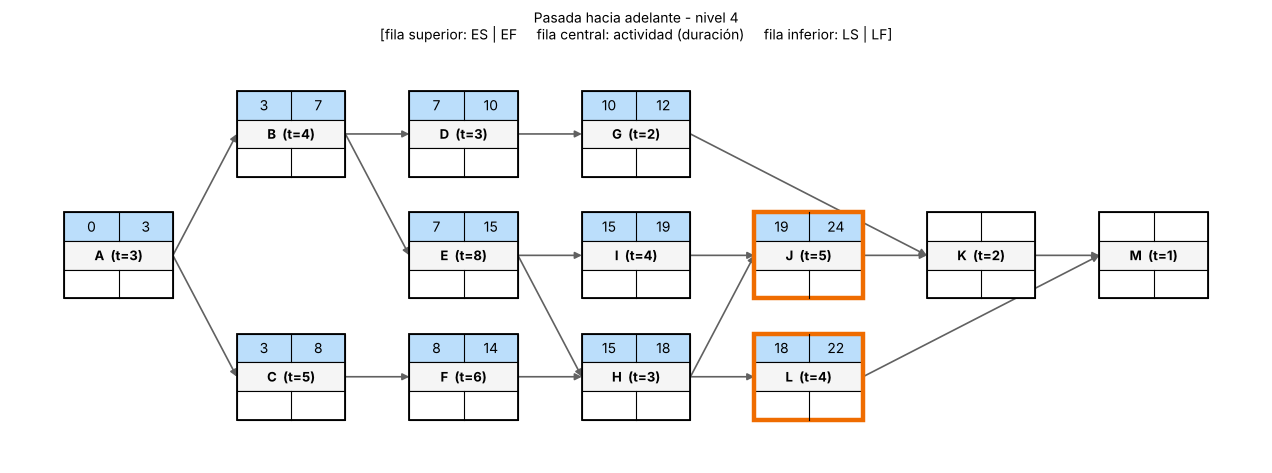

In [9]:
nivel, filas = next(adelante)
mostrar_adelante(nivel, filas)

### Nivel 5

Nivel 5 — **K** espera a G y a J (toma el mayor de los dos).

PASADA HACIA ADELANTE - Nivel 5: actividades ['K']

  Actividad K:  ES = max(EF_G=12, EF_J=24) = 24   ->   EF = ES + t = 24 + 2 = 26


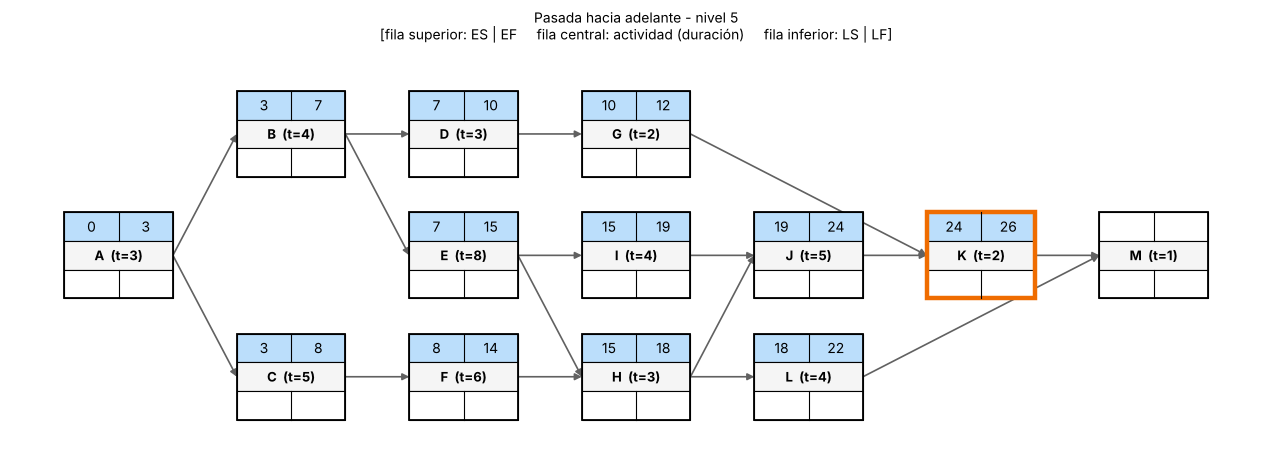

In [10]:
nivel, filas = next(adelante)
mostrar_adelante(nivel, filas)

### Nivel 6

Nivel 6 — **M** (última actividad) espera a K y a L. Su $EF$ es la **duración del proyecto**.

PASADA HACIA ADELANTE - Nivel 6: actividades ['M']

  Actividad M:  ES = max(EF_K=26, EF_L=22) = 26   ->   EF = ES + t = 26 + 1 = 27


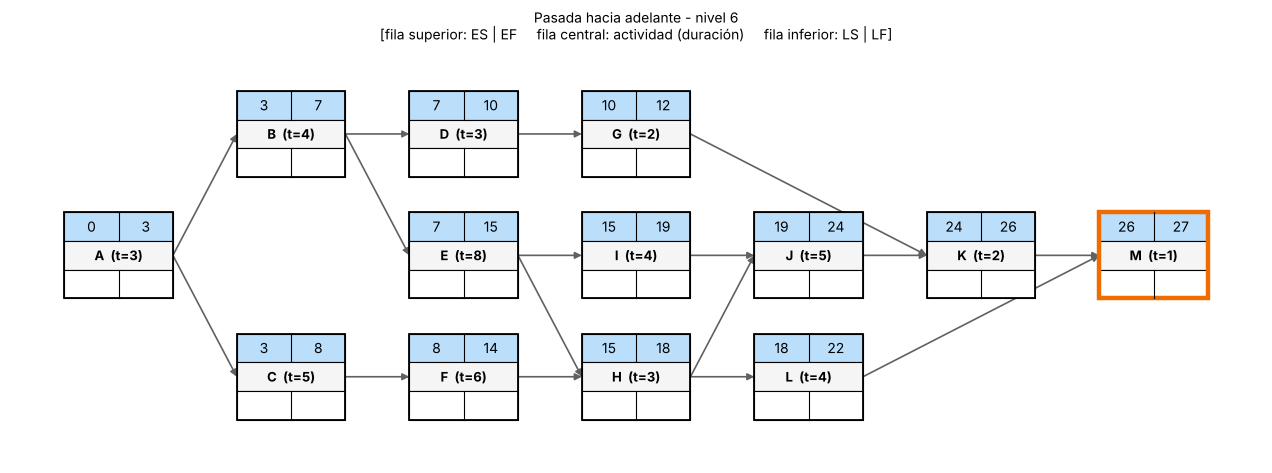

In [11]:
nivel, filas = next(adelante)
mostrar_adelante(nivel, filas)

---
## 7.2 Duración del proyecto e inicio de la pasada hacia atrás

La duración del proyecto es el **mayor $EF$** de todas las actividades. Ese valor es el $LF$ de las actividades finales (aquellas sin sucesoras).

La **pasada hacia atrás** recorre los niveles en orden inverso. Para cada actividad:

1. $LF$ = el **mínimo** de los $LS$ de sus sucesoras ($T$ si no tiene sucesoras).
2. $LS = LF - t$ (**resta**).

Duración del proyecto  T = máx(EF) = 27 días


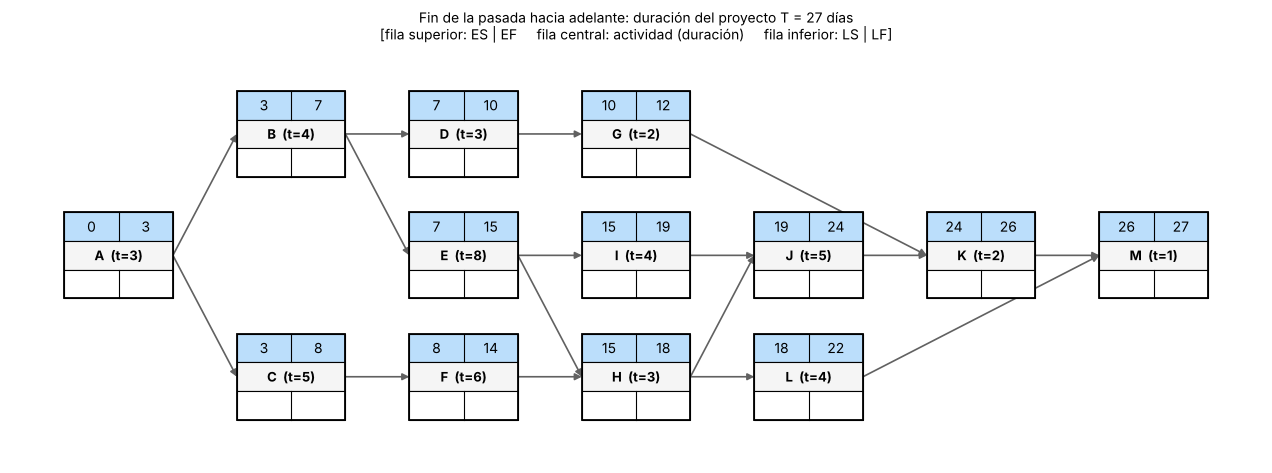

In [12]:
T = max(v["EF"] for v in vals.values())
print("Duración del proyecto  T = máx(EF) =", T, "días")

def pasada_atras():
    for nivel in range(len(gens) - 1, -1, -1):
        filas = []
        for k in gens[nivel]:
            sucs = list(G.successors(k))
            LF = min([vals[s]["LS"] for s in sucs], default=T)
            LS = LF - dur[k]
            vals[k]["LS"], vals[k]["LF"] = LS, LF
            if sucs:
                lista = ", ".join("LS_" + s + "=" + str(vals[s]["LS"]) for s in sucs)
                f_lf = "LF = min(" + lista + ") = " + str(LF)
            else:
                f_lf = "LF = T = " + str(T) + " (no tiene sucesoras)"
            f_ls = "LS = LF - t = " + str(LF) + " - " + str(dur[k]) + " = " + str(LS)
            filas.append((k, f_lf, f_ls))
        yield nivel, filas


def mostrar_atras(nivel, filas):
    print(f"PASADA HACIA ATRÁS - Nivel {nivel}: actividades {gens[nivel]}\n")
    for k, f_lf, f_ls in filas:
        print(f"  Actividad {k}:  {f_lf}   ->   {f_ls}")
    dibujar_red(vals, f"Pasada hacia atrás - nivel {nivel}", resaltar=gens[nivel])


atras = pasada_atras()
dibujar_red(vals, f"Fin de la pasada hacia adelante: duración del proyecto T = {T} días")

---
## 7.3 Pasada hacia atrás (resta): $LF$ y $LS$

Se recorre desde el nivel 6 hasta el nivel 0. Cuando una actividad tiene **varias sucesoras** (por ejemplo B, E, H) su $LF$ es el **mínimo** de los $LS$ de ellas.

### Paso 1 de la pasada hacia atrás

Nivel 6 — **M** no tiene sucesoras: $LF=T=27$.

PASADA HACIA ATRÁS - Nivel 6: actividades ['M']

  Actividad M:  LF = T = 27 (no tiene sucesoras)   ->   LS = LF - t = 27 - 1 = 26


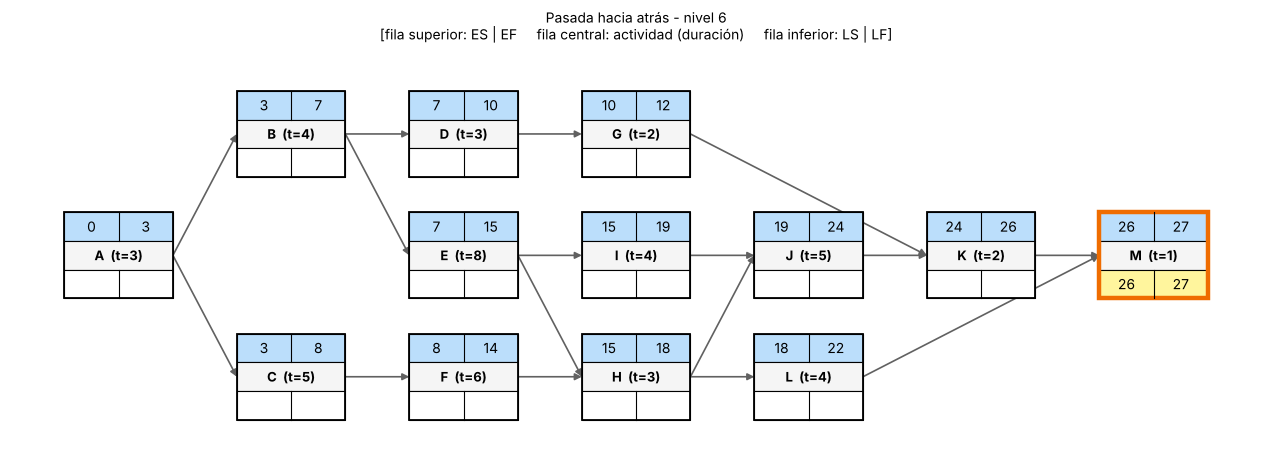

In [13]:
nivel, filas = next(atras)
mostrar_atras(nivel, filas)

### Paso 2 de la pasada hacia atrás

Nivel 5 — **K** precede sólo a M.

PASADA HACIA ATRÁS - Nivel 5: actividades ['K']

  Actividad K:  LF = min(LS_M=26) = 26   ->   LS = LF - t = 26 - 2 = 24


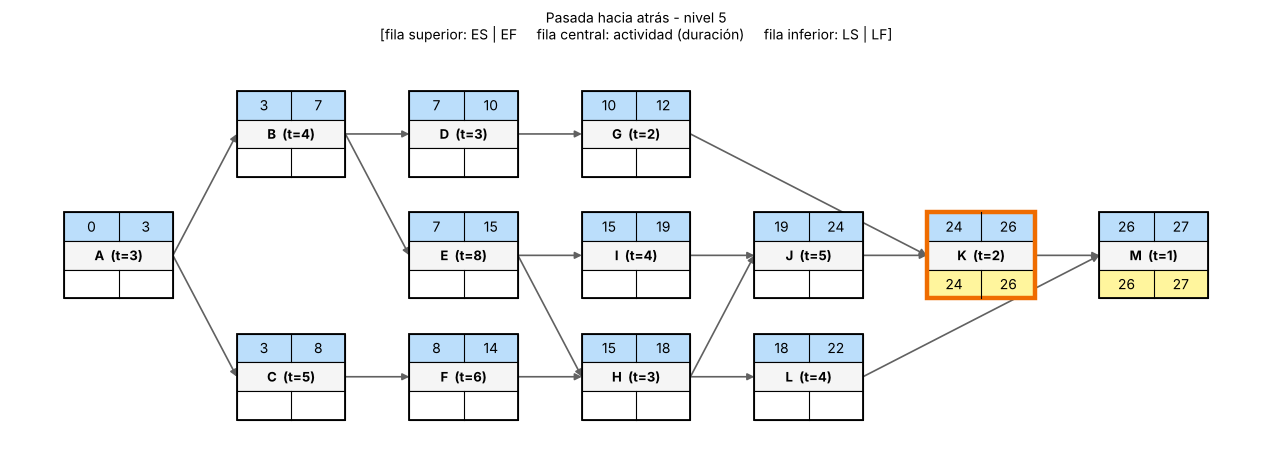

In [14]:
nivel, filas = next(atras)
mostrar_atras(nivel, filas)

### Paso 3 de la pasada hacia atrás

Nivel 4 — **J** precede a K; **L** precede a M.

PASADA HACIA ATRÁS - Nivel 4: actividades ['J', 'L']

  Actividad J:  LF = min(LS_K=24) = 24   ->   LS = LF - t = 24 - 5 = 19
  Actividad L:  LF = min(LS_M=26) = 26   ->   LS = LF - t = 26 - 4 = 22


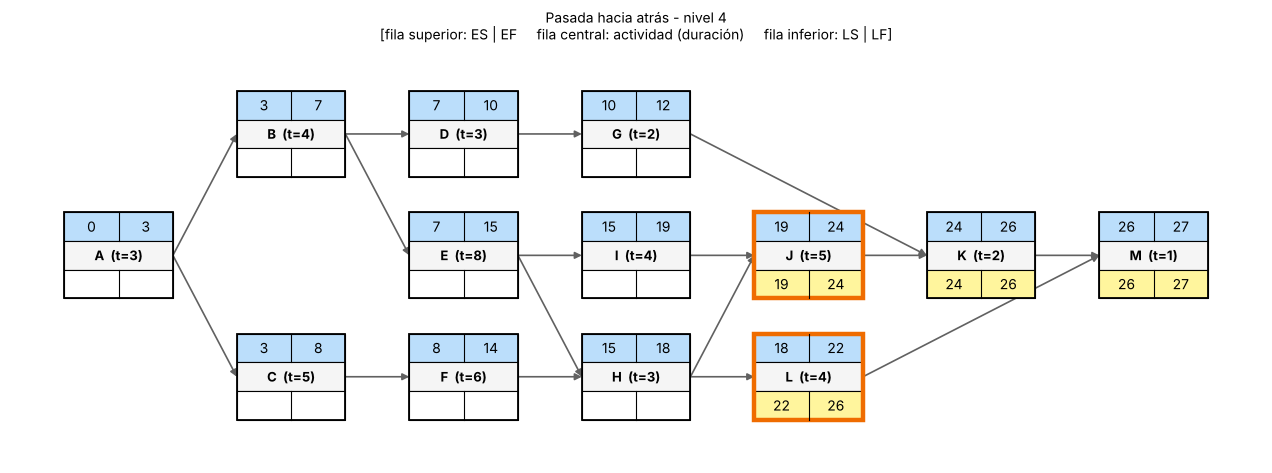

In [15]:
nivel, filas = next(atras)
mostrar_atras(nivel, filas)

### Paso 4 de la pasada hacia atrás

Nivel 3 — **G** precede a K; **I** precede a J; **H** precede a J y a L (toma el **menor** $LS$).

PASADA HACIA ATRÁS - Nivel 3: actividades ['G', 'H', 'I']

  Actividad G:  LF = min(LS_K=24) = 24   ->   LS = LF - t = 24 - 2 = 22
  Actividad H:  LF = min(LS_J=19, LS_L=22) = 19   ->   LS = LF - t = 19 - 3 = 16
  Actividad I:  LF = min(LS_J=19) = 19   ->   LS = LF - t = 19 - 4 = 15


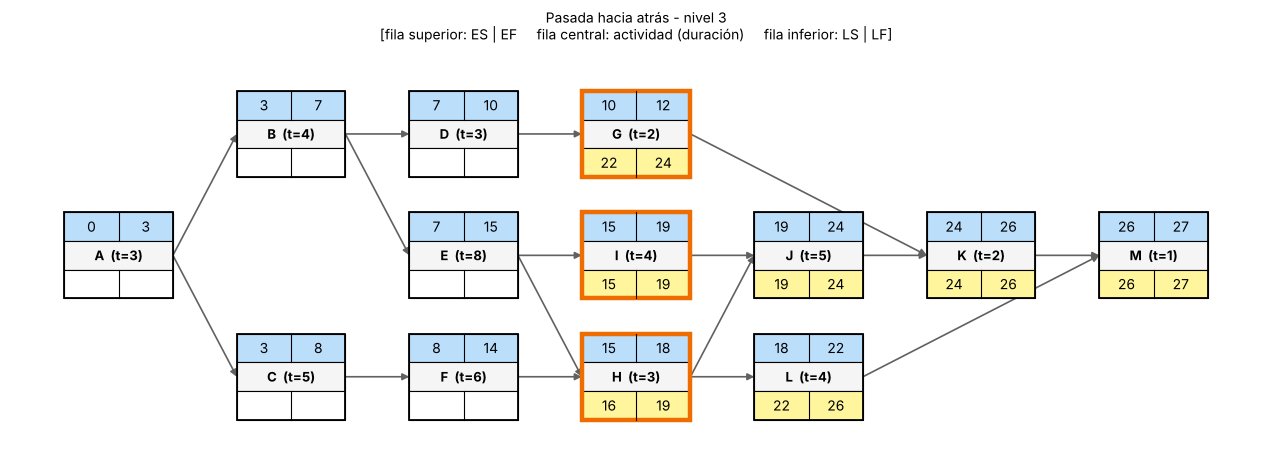

In [16]:
nivel, filas = next(atras)
mostrar_atras(nivel, filas)

### Paso 5 de la pasada hacia atrás

Nivel 2 — **D** precede a G; **E** precede a H e I; **F** precede a H.

PASADA HACIA ATRÁS - Nivel 2: actividades ['D', 'E', 'F']

  Actividad D:  LF = min(LS_G=22) = 22   ->   LS = LF - t = 22 - 3 = 19
  Actividad E:  LF = min(LS_H=16, LS_I=15) = 15   ->   LS = LF - t = 15 - 8 = 7
  Actividad F:  LF = min(LS_H=16) = 16   ->   LS = LF - t = 16 - 6 = 10


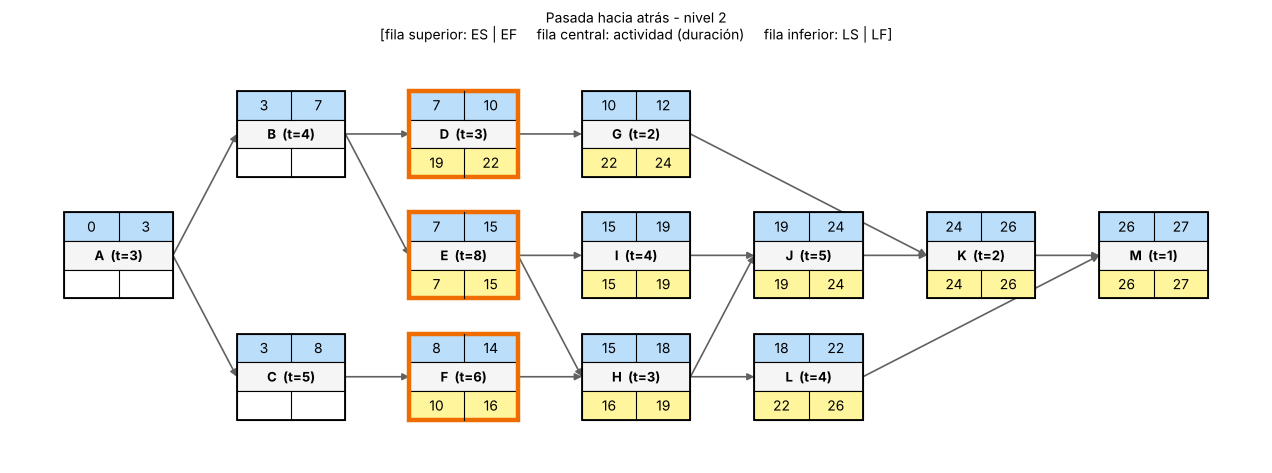

In [17]:
nivel, filas = next(atras)
mostrar_atras(nivel, filas)

### Paso 6 de la pasada hacia atrás

Nivel 1 — **B** precede a D y E; **C** precede a F.

PASADA HACIA ATRÁS - Nivel 1: actividades ['B', 'C']

  Actividad B:  LF = min(LS_D=19, LS_E=7) = 7   ->   LS = LF - t = 7 - 4 = 3
  Actividad C:  LF = min(LS_F=10) = 10   ->   LS = LF - t = 10 - 5 = 5


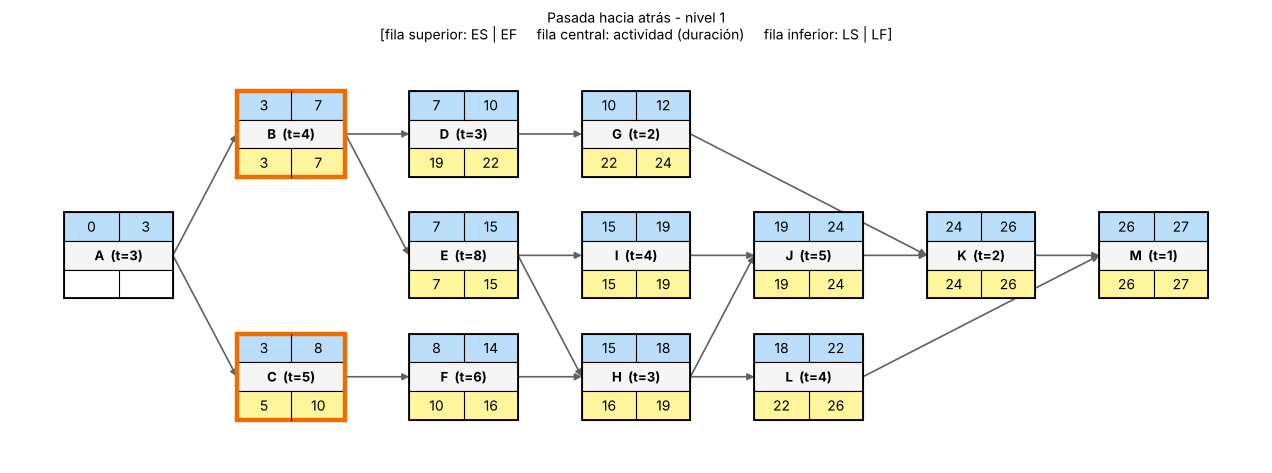

In [18]:
nivel, filas = next(atras)
mostrar_atras(nivel, filas)

### Paso 7 de la pasada hacia atrás

Nivel 0 — **A** precede a B y C. Debe resultar $LS_A=0$, lo que valida el cálculo.

PASADA HACIA ATRÁS - Nivel 0: actividades ['A']

  Actividad A:  LF = min(LS_B=3, LS_C=5) = 3   ->   LS = LF - t = 3 - 3 = 0


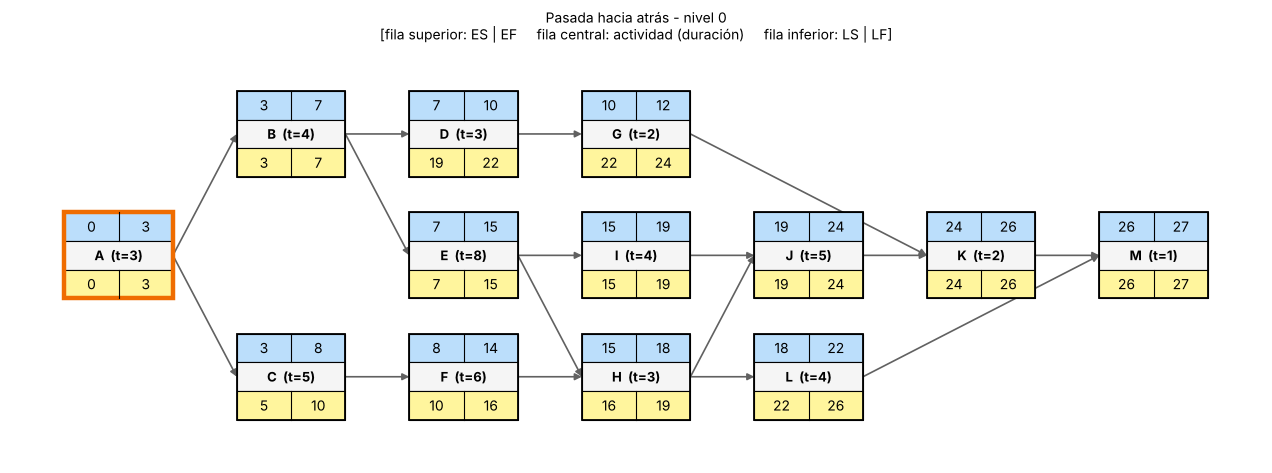

In [19]:
nivel, filas = next(atras)
mostrar_atras(nivel, filas)

---
## 7.4 Cálculo de holguras y tabla de resultados

Con los cuatro tiempos de cada actividad se calcula la holgura $H=LS-ES$ y se comprueba que coincide con $LF-EF$. Las actividades con **holgura = 0** son las **críticas**. Los resultados se guardan en `p2_resultados_cpm.csv`.

Act  t Precedentes  ES  EF  LS  LF  Holgura Crítica
  A  3           -   0   3   0   3        0      SÍ
  B  4           A   3   7   3   7        0      SÍ
  C  5           A   3   8   5  10        2      no
  D  3           B   7  10  19  22       12      no
  E  8           B   7  15   7  15        0      SÍ
  F  6           C   8  14  10  16        2      no
  G  2           D  10  12  22  24       12      no
  H  3        E, F  15  18  16  19        1      no
  I  4           E  15  19  15  19        0      SÍ
  J  5        H, I  19  24  19  24        0      SÍ
  K  2        G, J  24  26  24  26        0      SÍ
  L  4           H  18  22  22  26        4      no
  M  1        K, L  26  27  26  27        0      SÍ

Actividades críticas (holgura = 0): ['A', 'B', 'E', 'I', 'J', 'K', 'M']
Duración total del proyecto        : 27 días


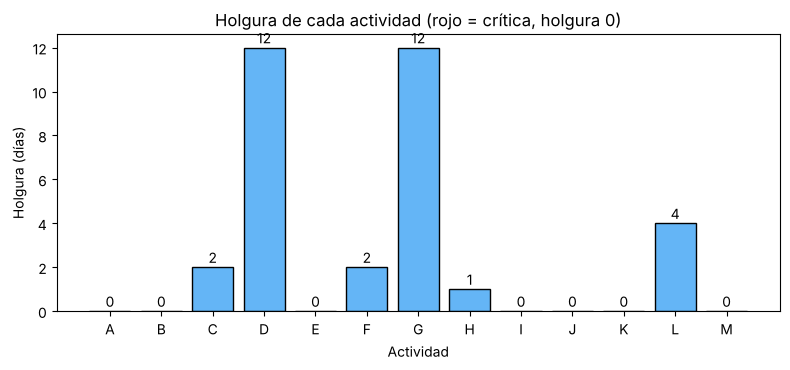

In [20]:
filas = []
for k in actividades:
    v = vals[k]
    holgura = v["LS"] - v["ES"]
    assert holgura == v["LF"] - v["EF"], "La holgura LS-ES debe coincidir con LF-EF"
    filas.append([k, dur[k], ", ".join(actividades[k][2]) or "-", v["ES"], v["EF"], v["LS"], v["LF"],
                  holgura, "SÍ" if holgura == 0 else "no"])

df_res = pd.DataFrame(filas, columns=["Act", "t", "Precedentes", "ES", "EF", "LS", "LF", "Holgura", "Crítica"])
df_res.to_csv("p2_resultados_cpm.csv", index=False)
print(df_res.to_string(index=False))

criticas = [r[0] for r in filas if r[7] == 0]
print("\nActividades críticas (holgura = 0):", criticas)
print("Duración total del proyecto        :", T, "días")

fig, ax = plt.subplots(figsize=(8, 3.8))
colores = ["#e53935" if h == 0 else "#64b5f6" for h in df_res["Holgura"]]
ax.bar(df_res["Act"], df_res["Holgura"], color=colores, edgecolor="black")
for i, h in enumerate(df_res["Holgura"]):
    ax.text(i, h + 0.2, str(h), ha="center")
ax.set_xlabel("Actividad"); ax.set_ylabel("Holgura (días)")
ax.set_title("Holgura de cada actividad (rojo = crítica, holgura 0)")
plt.tight_layout()
plt.show()

---
## 7.5 Análisis de trayectorias y ruta crítica

Otra forma de obtener la ruta crítica, como en el análisis de trayectorias visto en clase, es **enumerar todos los caminos** del inicio al fin del proyecto y sumar las duraciones: **la ruta más larga es la ruta crítica** y su longitud es la duración del proyecto.

Trayectorias del inicio al fin del proyecto:

  A - B - E - I - J - K - M = 3 + 4 + 8 + 4 + 5 + 2 + 1 = 27 días
  A - B - E - H - J - K - M = 3 + 4 + 8 + 3 + 5 + 2 + 1 = 26 días
  A - C - F - H - J - K - M = 3 + 5 + 6 + 3 + 5 + 2 + 1 = 25 días
  A - B - E - H - L - M  = 3 + 4 + 8 + 3 + 4 + 1  = 23 días
  A - C - F - H - L - M  = 3 + 5 + 6 + 3 + 4 + 1  = 22 días
  A - B - D - G - K - M  = 3 + 4 + 3 + 2 + 2 + 1  = 15 días

RUTA CRÍTICA: A -> B -> E -> I -> J -> K -> M (27 días)
¿Coincide con las actividades de holgura 0? -> True


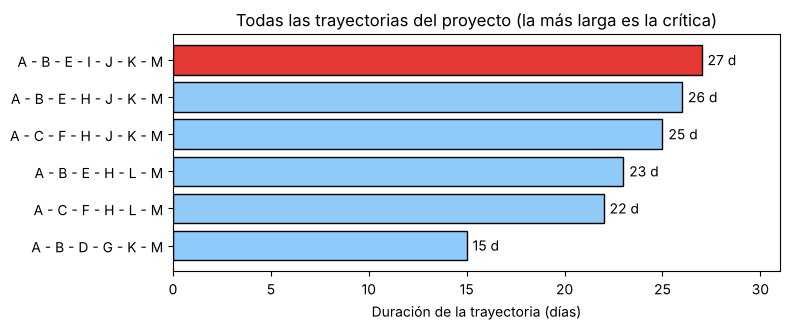

In [21]:
inicio = [k for k in G if G.in_degree(k) == 0]
fin = [k for k in G if G.out_degree(k) == 0]

caminos = []
for i in inicio:
    for f in fin:
        for c in nx.all_simple_paths(G, i, f):
            caminos.append((sum(dur[x] for x in c), c))
caminos.sort(reverse=True)

print("Trayectorias del inicio al fin del proyecto:\n")
for L_, c in caminos:
    suma = " + ".join(str(dur[x]) for x in c)
    print(f"  {' - '.join(c):<22} = {suma:<22} = {L_} días")

ruta_critica = caminos[0][1]
print("\nRUTA CRÍTICA:", " -> ".join(ruta_critica), f"({caminos[0][0]} días)")
print("¿Coincide con las actividades de holgura 0? ->", set(ruta_critica) == set(criticas))

fig, ax = plt.subplots(figsize=(8, 3.4))
etiq = [" - ".join(c) for _, c in caminos]
ax.barh(etiq[::-1], [l for l, _ in caminos][::-1],
        color=["#e53935" if i == 0 else "#90caf9" for i in range(len(caminos))][::-1], edgecolor="black")
for i, (l, _) in enumerate(caminos[::-1]):
    ax.text(l + 0.3, i, f"{l} d", va="center")
ax.set_xlabel("Duración de la trayectoria (días)")
ax.set_title("Todas las trayectorias del proyecto (la más larga es la crítica)")
ax.set_xlim(0, T + 4)
plt.tight_layout()
plt.show()

## 7.6 Red final con la ruta crítica resaltada

Se dibuja la red completa con todos los tiempos calculados. Los nodos y las flechas **en rojo** forman la ruta crítica.

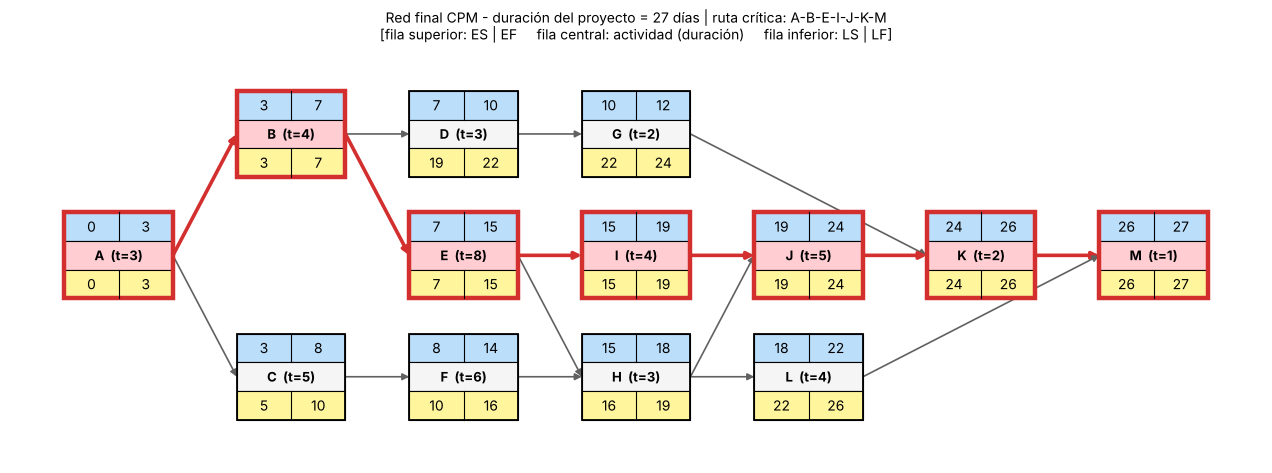

In [22]:
arcos_crit = list(zip(ruta_critica[:-1], ruta_critica[1:]))
dibujar_red(vals, f"Red final CPM - duración del proyecto = {T} días | ruta crítica: " + "-".join(ruta_critica),
            criticos=ruta_critica, arcos_criticos=arcos_crit)

---
## 7.7 Diagrama de Gantt

El diagrama de Gantt muestra el calendario del proyecto con el inicio más cercano. Las barras **rojas** son actividades críticas; en las demás, la franja **rayada** indica cuántos días de holgura tienen (pueden retrasarse sin afectar la fecha final).

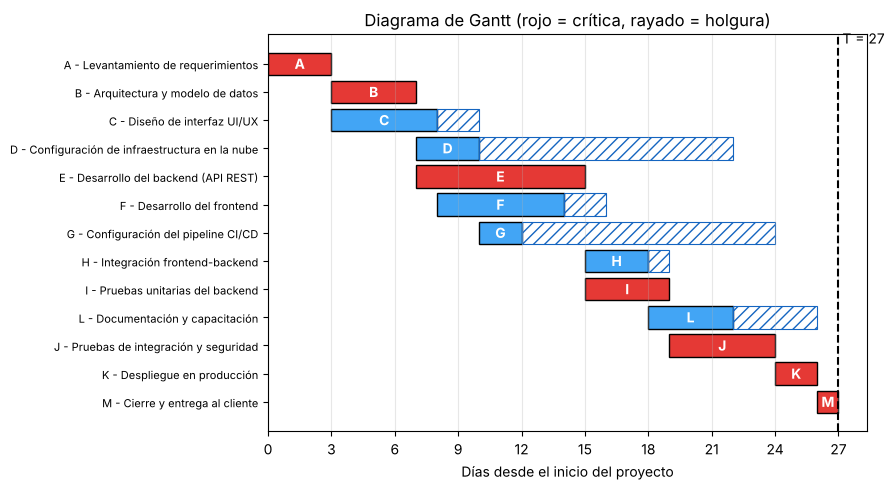

In [23]:
orden = sorted(actividades, key=lambda k: (vals[k]["ES"], k))
fig, ax = plt.subplots(figsize=(9, 5))
for i, k in enumerate(orden[::-1]):
    v = vals[k]
    crit = v["LS"] == v["ES"]
    ax.barh(i, dur[k], left=v["ES"], color="#e53935" if crit else "#42a5f5", edgecolor="black")
    if not crit:
        ax.barh(i, v["LS"] - v["ES"], left=v["EF"], color="none", edgecolor="#1565c0", hatch="///", lw=0.8)
    ax.text(v["ES"] + dur[k] / 2, i, k, ha="center", va="center", color="white", fontweight="bold")
ax.set_yticks(range(len(orden)))
ax.set_yticklabels([f"{k} - {actividades[k][0]}" for k in orden[::-1]], fontsize=8)
ax.set_xlabel("Días desde el inicio del proyecto")
ax.set_xticks(range(0, T + 2, 3))
ax.axvline(T, color="black", ls="--")
ax.text(T, len(orden) - 0.4, f" T = {T}", va="bottom")
ax.set_title("Diagrama de Gantt (rojo = crítica, rayado = holgura)")
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

---
## 7.8 Validación con NetworkX

Se comprueba el resultado con la función de **camino más largo en un grafo acíclico** de NetworkX (`dag_longest_path`). Para ello se asigna a cada arco la duración de la actividad de origen y se agrega un nodo final ficticio `FIN`.

In [24]:
H = nx.DiGraph()
for u, v in G.edges():
    H.add_edge(u, v, weight=dur[u])
for f in fin:
    H.add_edge(f, "FIN", weight=dur[f])
for i in inicio:
    H.add_edge("INICIO", i, weight=0)

cam = nx.dag_longest_path(H, weight="weight")
lon = nx.dag_longest_path_length(H, weight="weight")
print("Camino más largo según NetworkX :", " -> ".join(c for c in cam if c not in ("INICIO", "FIN")))
print("Longitud (duración del proyecto):", lon, "días")
print("¿Coincide con nuestra pasada hacia adelante/atrás? ->", lon == T and cam[1:-1] == ruta_critica)

Camino más largo según NetworkX : A -> B -> E -> I -> J -> K -> M
Longitud (duración del proyecto): 27 días
¿Coincide con nuestra pasada hacia adelante/atrás? -> True


---
## 7.9 Escenarios de retraso (¿qué pasa si una actividad se atrasa?)

La **holgura** permite predecir el efecto de un retraso: si el atraso es menor o igual a la holgura, el proyecto **no** se retrasa; si la supera, el proyecto se retrasa sólo por **el exceso**. Si la actividad es crítica, el retraso se transmite **completo**. Se recalcula la duración del proyecto con la pasada hacia adelante para varios escenarios.

Actividad  Retraso (d)  Holgura (d)  Nueva duración  Retraso del proyecto
        E            3            0              30                     3
        I            2            0              29                     2
        H            2            1              28                     1
        F            3            2              28                     1
        L            6            4              29                     2
        D            3           12              27                     0


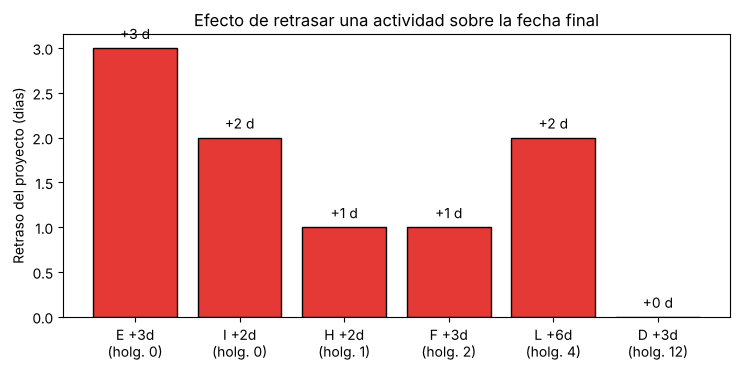

In [25]:
def duracion_proyecto(d):
    EF = {}
    for grupo in gens:
        for k in grupo:
            ES = max([EF[p] for p in G.predecessors(k)], default=0)
            EF[k] = ES + d[k]
    return max(EF.values())

escenarios = [("E", 3), ("I", 2), ("H", 2), ("F", 3), ("L", 6), ("D", 3)]
filas_e = []
for k, atraso in escenarios:
    d2 = dict(dur)
    d2[k] += atraso
    nueva = duracion_proyecto(d2)
    hol = vals[k]["LS"] - vals[k]["ES"]
    filas_e.append([k, atraso, hol, nueva, nueva - T])

df_esc = pd.DataFrame(filas_e, columns=["Actividad", "Retraso (d)", "Holgura (d)", "Nueva duración", "Retraso del proyecto"])
print(df_esc.to_string(index=False))

fig, ax = plt.subplots(figsize=(7.5, 3.8))
etq = [f"{k} +{a}d\n(holg. {h})" for k, a, h, _, _ in filas_e]
ax.bar(etq, df_esc["Retraso del proyecto"],
       color=["#e53935" if r > 0 else "#66bb6a" for r in df_esc["Retraso del proyecto"]], edgecolor="black")
for i, r in enumerate(df_esc["Retraso del proyecto"]):
    ax.text(i, r + 0.1, f"+{r} d", ha="center")
ax.set_ylabel("Retraso del proyecto (días)")
ax.set_title("Efecto de retrasar una actividad sobre la fecha final")
plt.tight_layout()
plt.show()


---
# 8. Interpretación de resultados y análisis final

**Resultado principal.** El proyecto dura **27 días** y su **ruta crítica** es:

$$A \rightarrow B \rightarrow E \rightarrow I \rightarrow J \rightarrow K \rightarrow M \qquad (3+4+8+4+5+2+1=27 \text{ días})$$

| Actividad | t | ES | EF | LS | LF | Holgura | ¿Crítica? |
|:---:|:-:|:-:|:-:|:-:|:-:|:-:|:-:|
| A | 3 | 0 | 3 | 0 | 3 | 0 | **Sí** |
| B | 4 | 3 | 7 | 3 | 7 | 0 | **Sí** |
| C | 5 | 3 | 8 | 5 | 10 | 2 | no |
| D | 3 | 7 | 10 | 19 | 22 | 12 | no |
| E | 8 | 7 | 15 | 7 | 15 | 0 | **Sí** |
| F | 6 | 8 | 14 | 10 | 16 | 2 | no |
| G | 2 | 10 | 12 | 22 | 24 | 12 | no |
| H | 3 | 15 | 18 | 16 | 19 | 1 | no |
| I | 4 | 15 | 19 | 15 | 19 | 0 | **Sí** |
| J | 5 | 19 | 24 | 19 | 24 | 0 | **Sí** |
| K | 2 | 24 | 26 | 24 | 26 | 0 | **Sí** |
| L | 4 | 18 | 22 | 22 | 26 | 4 | no |
| M | 1 | 26 | 27 | 26 | 27 | 0 | **Sí** |

**Interpretación.**

- El proyecto **no puede terminar antes de 27 días**. Las **7 actividades críticas** (A, B, E, I, J, K, M) tienen holgura cero: cualquier retraso en ellas retrasa un día completo la entrega.
- Las actividades **D y G** (infraestructura y CI/CD) tienen **12 días de holgura**, y **L** (documentación) tiene 4: son las candidatas para **reasignar personal** hacia las actividades críticas si se quiere acelerar el proyecto.
- La trayectoria **A–B–E–H–J–K–M** dura 26 días, sólo **un día menos** que la crítica (la actividad H tiene 1 día de holgura). Es una ruta **casi crítica** que debe vigilarse: un pequeño retraso en H la convertiría también en crítica.
- El análisis de escenarios confirma la teoría: retrasar **E** (crítica) 3 días retrasa el proyecto 3 días; retrasar **F** 3 días (holgura 2) lo retrasa sólo 1 día; retrasar **L** 6 días (holgura 4) lo retrasa sólo 2 días, y retrasar **D** 3 días (holgura 12) no afecta la fecha final.
- Los resultados obtenidos con la pasada hacia adelante y hacia atrás coinciden con el análisis de trayectorias y con la validación de NetworkX.

**Aplicación al área de Tecnologías de la Información.**

- En un proyecto de software o de migración a la nube, CPM indica **qué tareas protege el líder técnico** (el backend, las pruebas unitarias y las pruebas de integración y seguridad) y **dónde hay margen de maniobra** (infraestructura, CI/CD y documentación).
- Si se quiere reducir el tiempo de entrega, se debe **acelerar una actividad crítica** (por ejemplo, agregar desarrolladores al *backend* E o automatizar las pruebas I y J); acelerar actividades con holgura (como D o G) **no reduce** la duración del proyecto.
- Al reducir una actividad crítica es importante recalcular la red, porque la ruta casi crítica (26 días) podría pasar a ser la nueva ruta crítica.

---

# 9. Conclusiones individuales y del equipo

## Conclusión del equipo

El método de la ruta crítica permitió determinar que el proyecto de desarrollo y despliegue de la aplicación web dura **27 días** y que sólo **7 de las 13 actividades** controlan la fecha final. La implementación en Python de las pasadas hacia adelante (sumas) y hacia atrás (restas), graficada nivel por nivel sobre la red AEN, hizo evidente el origen de cada tiempo y de cada holgura. Se validó el resultado con el análisis de trayectorias y con NetworkX, y se observó la utilidad del modelo para priorizar recursos y evaluar el impacto de retrasos en proyectos de TI.

## Conclusiones individuales

**Integrante 1 – Fernando Dante Rodriguez Silva:** La aplicación del Método de la Ruta Crítica (CPM) sobre un grafo dirigido acíclico permite transformar las dependencias lógicas de un proyecto de ingeniería de software en un modelo matemático cuantificable. A través de las pasadas hacia adelante y hacia atrás se determinó que la duración mínima para poner en producción la aplicación web es de **27 días**, identificando con exactitud la secuencia crítica (**A → B → E → I → J → K → M**). Este enfoque demuestra que la optimización de tiempos en proyectos tecnológicos no depende de acelerar todas las tareas por igual, sino de controlar estrictamente aquellas cuya holgura es nula.

**Integrante 2 – Jonathan Alberto López Fabián:**  La implementación algorítmica del modelo en Python utilizando **NetworkX** y **Matplotlib** automatiza el cálculo de los tiempos más cercanos ($ES, EF$) y más lejanos ($LS, LF$) mediante generaciones topológicas, evitando errores manuales en redes con múltiples predecesoras y sucesoras. Asimismo, la representación visual paso a paso de los nodos AEN facilita la validación del comportamiento del algoritmo en cada nivel de la red y proporciona una herramienta reproducible y escalable para planificar proyectos con decenas de actividades.

**Integrante 3 – Brayan Michel Aguilar Torres:** Desde la perspectiva de la gestión de proyectos y operaciones DevOps, el cálculo de las holguras ofrece información estratégica para la asignación de recursos y el control de riesgos. Mientras que tareas como la configuración de infraestructura en la nube (**D**) y el *pipeline* CI/CD (**G**) cuentan con una holgura de **12 días** que permite absorber imprevistos sin afectar la entrega final, actividades como el desarrollo del *backend* (**E**) o las pruebas de integración y seguridad (**J**) no admiten retrasos, mientras que la integración *frontend-backend* (**H**) requiere vigilancia cercana al disponer de apenas **1 día** de margen.